# Part 5: How do you grade a prediction you can never check?

*Series: Who Will Stay Because of Us? Uplift Modelling and Causal Inference for Client Attrition*

In Part 4 we checked the T-learner against the true uplift. A real bank cannot do that. For any single client, uplift is invisible: they either got pricing or they did not, never both. So how does anyone know whether an uplift model works?

**In this notebook**

1. Why uplift has to be checked on **groups**, not clients.
2. The uplift-by-decile table: line clients up by predicted uplift, cut the line into ten rooms, measure each room.
3. Reading it for **shape** (does the ranking work?) and **size** (are the numbers right?).
4. How much the table wobbles from chance alone, and why five bins can beat ten.
5. The Qini curve, the Qini coefficient and uplift@k.

Only at the very end do we peek at the true uplift, to confirm the checks told the truth.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_series import SERIES_SEED, analysis_pool, generate_bank
from uplift_series import plotting as P
from uplift_series.evaluation import (assign_bins, bootstrap_uplift_by_bin, qini_coefficient,
                                      qini_curve, uplift_at_k, uplift_by_bin)
from uplift_series.modeling import TLearner, split_pool

P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)

df = generate_bank(assignment="random", seed=SERIES_SEED)
train, test = split_pool(analysis_pool(df), test_size=0.3, seed=0)
test["pred_uplift"] = TLearner().fit(train).predict_uplift(test)
print(f"{len(test):,} test clients: {test['treated'].sum()} treated, {(test['treated'] == 0).sum()} control")

1,500 test clients: 300 treated, 1200 control


## 1. Check groups, not clients

Picture every client with an invisible twin in a parallel world. Client 417 got a pricing call and stayed; in the other world nobody called, and we will never know what happened there. The model said client 417's uplift was 23 points. No fact can confirm or refute that.

But a **group** of similar clients contains both kinds: some got pricing, some did not. Their churn rates show both worlds at once. The difference is the group's actual uplift.

## 2. Ten rooms

Line up the 1,500 test clients by predicted uplift, highest first. Treated and control clients stand in the same line, scattered throughout, because pricing was given at random. Cut the line into ten equal rooms of 150 clients (deciles). Each room holds roughly 30 treated and 120 control clients.

In each room:

> **actual uplift = control churn rate − treated churn rate**

In [2]:
deciles = uplift_by_bin(test, "pred_uplift", n_bins=10)
deciles

,clients,treated,control,treated_churn,control_churn,actual_uplift,predicted_uplift
bin,,,,,,,
1,150,29,121,0.241,0.380,0.139,0.266
2,150,28,122,0.214,0.279,0.064,0.191
3,150,29,121,0.103,0.248,0.144,0.161
4,150,40,110,0.075,0.236,0.161,0.139
5,150,30,120,0.133,0.158,0.025,0.119
6,150,40,110,0.100,0.155,0.055,0.093
7,150,24,126,0.250,0.183,-0.067,0.061
8,150,31,119,0.129,0.193,0.064,0.023
9,150,24,126,0.292,0.254,-0.038,-0.025


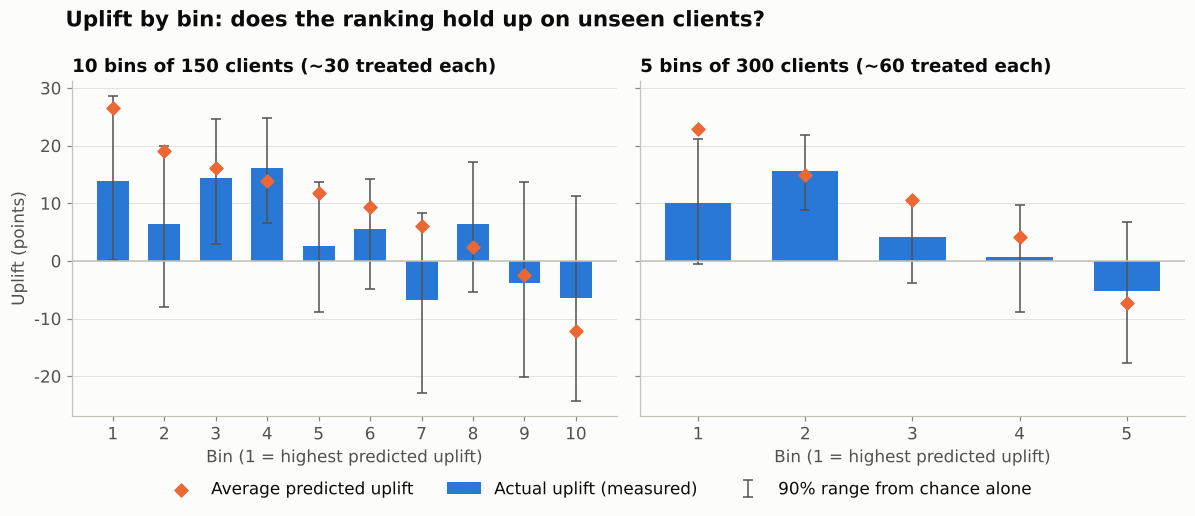

In [3]:
ci10 = bootstrap_uplift_by_bin(test, "pred_uplift", n_bins=10, n_boot=300, seed=0)
quintiles = uplift_by_bin(test, "pred_uplift", n_bins=5)
ci5 = bootstrap_uplift_by_bin(test, "pred_uplift", n_bins=5, n_boot=300, seed=0)

def bin_chart(ax, table, ci, title):
    x = np.arange(1, len(table) + 1)
    ax.bar(x, table["actual_uplift"], color=P.BLUE, width=0.62, label="Actual uplift (measured)")
    ax.errorbar(x, table["actual_uplift"],
                yerr=[table["actual_uplift"] - ci["lower"], ci["upper"] - table["actual_uplift"]],
                fmt="none", ecolor=P.INK_SECONDARY, elinewidth=1, capsize=3,
                label="90% range from chance alone")
    ax.scatter(x, table["predicted_uplift"], marker="D", s=36, color=P.ORANGE, zorder=3,
               label="Average predicted uplift")
    ax.axhline(0, color=P.BASELINE, linewidth=1)
    ax.set_xticks(x)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v * 100:.0f}")
    ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=12)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
bin_chart(axes[0], deciles, ci10, "10 bins of 150 clients (~30 treated each)")
bin_chart(axes[1], quintiles, ci5, "5 bins of 300 clients (~60 treated each)")
axes[0].set_ylabel("Uplift (points)")
for ax in axes:
    ax.set_xlabel("Bin (1 = highest predicted uplift)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Uplift by bin: does the ranking hold up on unseen clients?", x=0.06, ha="left",
             fontsize=14, fontweight="bold")
fig.tight_layout()
P.save(fig, "05_uplift_by_bin")
plt.show()

## 3. Reading the table: shape and size

**Shape: does the ranking work?** Read the actual uplift from bin 1 downwards. With ten bins the bars bounce around, but the top bins are clearly positive and the bottom bins hover at or below zero. With five bins the pattern is easier to see: high at the front of the line, falling to around zero and below at the back. The rooms the model put first really are the rooms where pricing does the most good. That is the property targeting depends on.

**Size: can the numbers be trusted?** Compare the orange diamonds with the bars. In the top bins the model *predicts* more uplift than it *delivers*. This is a well-known effect: the clients ranked first are partly there because the model overestimated them, so the very top of any ranking tends to be optimistic. For choosing *who* to call this hardly matters; for converting uplift into money (Part 7) it does.

**What failure would look like:**

- a flat pattern, every bin about the same: the model cannot tell persuadables from anyone else;
- a jumbled pattern that rises and falls at random: the same, with noise on top;
- a pattern that *rises* from bin 1 to the last bin: the uplift was almost certainly computed backwards (treated minus control).

## 4. The wobble

The thin vertical lines show how much each bar would move if we had drawn a different sample of the same size (bootstrap resampling, 90% range). With only about 30 treated clients per decile, one extra churner moves a decile's treated churn rate by more than three points, and the ranges are wider than the differences between neighbouring bars.

Two practical rules follow:

- with a few hundred treated clients in the test set, use **five bins**, not ten;
- judge the **overall shape**, never a single bar.

## 5. From bins to curves

Bins are good for explaining a model to the business. To compare models, it helps to have one curve and one number.

Imagine targeting clients in the model's order: the first 10% of the line, then the first 20%, and so on. At each point, ask: *how many extra clients have we kept compared with not calling?* Plotting that gives the **Qini curve**. A good model climbs steeply at first, because the best opportunities come first, then flattens.

The straight line from zero to the end point is what calling clients in **random** order would achieve. The area between the model's curve and that line is the **Qini coefficient**: positive beats random, zero is no better, negative is worse.

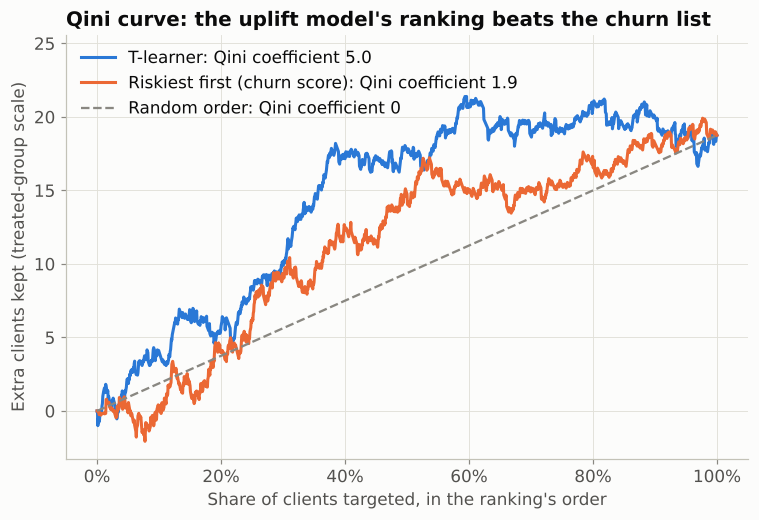

In [4]:
rankings = {"T-learner": "pred_uplift", "Riskiest first (churn score)": "churn_score"}

fig, ax = plt.subplots(figsize=(8, 5))
colors = [P.BLUE, P.ORANGE]
for (name, col), color in zip(rankings.items(), colors):
    curve = qini_curve(test, col)
    qc = qini_coefficient(test, col)
    ax.plot(curve["fraction"], curve["qini"], color=color, linewidth=2,
            label=f"{name}: Qini coefficient {qc:.1f}")
end = qini_curve(test, "pred_uplift")["qini"].iloc[-1]
ax.plot([0, 1], [0, end], color=P.INK_MUTED, linestyle="--", linewidth=1.5,
        label="Random order: Qini coefficient 0")
ax.legend(loc="upper left")
P.percent_axis(ax, "x")
ax.set_xlabel("Share of clients targeted, in the ranking's order")
ax.set_ylabel("Extra clients kept (treated-group scale)")
ax.set_ylim(bottom=min(0, ax.get_ylim()[0]), top=ax.get_ylim()[1] + 3)
ax.set_title("Qini curve: the uplift model's ranking beats the churn list")
P.save(fig, "05_qini_curve")
plt.show()

### Uplift@k: the number that matches RM capacity

The Qini coefficient summarises every possible cut-off. The business usually cares about one: the share of clients RMs can actually call. **Uplift@k** is the actual uplift among the top *k* share of the ranking.

In [5]:
at_k = pd.DataFrame({
    name: {f"top {int(k * 100)}%": 100 * uplift_at_k(test, col, k) for k in (0.1, 0.2, 0.3)}
    for name, col in rankings.items()
})
at_k.loc["all clients"] = 100 * uplift_at_k(test, "pred_uplift", 1.0)
at_k.round(1).rename_axis("actual uplift, points")

,T-learner,Riskiest first (churn score)
"actual uplift, points",,
top 10%,13.900,1.100
top 20%,10.100,6.700
top 30%,11.600,10.300
all clients,6.200,6.200


If RMs can call the top 20% of the line, the T-learner's selection shows a clearly larger actual drop in churn than the riskiest 20%. That is the number to put in front of the business.

## 6. Behind the curtain

Everything above used only what a real bank would have: who got pricing and who left. Now, for once, compare each bin's measured uplift with the true uplift of the clients in it.

In [6]:
check = quintiles[["actual_uplift", "predicted_uplift"]].copy()
check["true_uplift"] = test.groupby(assign_bins(test, "pred_uplift", 5))["true_uplift"].mean()
(100 * check).round(1).rename_axis("bin (5 bins)")

,actual_uplift,predicted_uplift,true_uplift
bin (5 bins),,,
1,10.100,22.800,14.100
2,15.500,15.000,12.100
3,4.200,10.600,8.200
4,0.600,4.200,3.200
5,-5.200,-7.300,0.200


The true uplift falls steadily from the first bin to the last, just as the measured table suggested, and the measured values sit around the truth with the wobble we saw. The predicted values at the top are too high, confirming the optimism noted above. The checks told the truth, without ever needing it.

## Takeaways

- Uplift cannot be checked for one client, but it **can** be measured for a group: control churn minus treated churn.
- **Uplift by bin** is the main validation tool. Read it for **shape** (does actual uplift fall from the first bin to the last?) and **size** (do predictions match?).
- Small groups wobble. With a few hundred treated clients, use **five bins** and judge the overall pattern.
- The **Qini curve and coefficient** compare models across every cut-off; **uplift@k** answers the business question at RM capacity.
- Expect the very top of a ranking to be **optimistic** about size.

**Next, Part 6:** the metrics every churn modeller knows (AUC, PR-AUC, KS, Gini, log loss), what they can still tell you, and how two churn models with good AUC can still produce a useless uplift ranking.